# Canary Selection

In [193]:
SETUPS = {
    "GROK_MNIST_MSE_MLP": "(I) MLP (MSE)\nGrokking",
    "NO_GROK_MNIST_MSE_MLP": "(II) MLP (MSE)\nNo Grokking",
    "GROK_MNIST_CE_MLP": "(III) MLP (CE)\nGrokking",
    "NO_GROK_MNIST_CE_MLP": "(IV) MLP (CE)\nNo Grokking",
    "GROK_MNIST_CE_VIT": "(V) ViT (CE)\nGrokking",
    "NO_GROK_MNIST_CE_VIT": "(VI) ViT (CE)\nNo Grokking",
    "GROK_MADD_CE_TRANSFORMER": "(VII) MADD (CE)\nGrokking"
}

## Setup

In [194]:
import matplotlib.pyplot as plt
import polars as pl
import polars.selectors as cs

from matplotlib.ticker import MultipleLocator, EngFormatter

In [195]:
info_rmia_df = pl.read_parquet("../../cache/canary-selection-v1/informia_results.parquet")
info_rmia_df = info_rmia_df.with_columns(pl.col("run_name").str.extract(pattern, group_index=1).replace(SETUPS).alias("title"))

In [196]:
pattern = "(" + "|".join([key for key in SETUPS.keys()]) + ")"
metrics_df = pl.read_parquet("../../cache/canary-selection-v1_mlflow_export.parquet")
metrics_df = metrics_df.pivot(index=["run_id", "run_name", "step", "timestamp"], on="metric_name", values="value", aggregate_function="first").sort(["run_id", "step"])
metrics_df = metrics_df.with_columns(pl.col("run_name").str.extract(pattern, group_index=1).replace(SETUPS).alias("title"), pl.from_epoch(pl.col("timestamp"), time_unit="ms").alias("timestamp"))

## Overview

In [197]:
info_rmia_df.head()

auc,tpr_at_0_fpr,tpr_at_0.01_fpr,tpr_at_0.05_fpr,tpr_at_0.1_fpr,step,optimal_a,optimal_a_auc,canary,run_name,id,target_run_id,val_run_id,ref_run_ids,run_ids,title
f64,f64,f64,f64,f64,i64,f64,f64,bool,str,str,str,str,list[str],list[str],str
0.487138,0.006,0.012,0.056,0.11,0,0.0,0.490878,false,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(VII) MADD (CE) Grokking"""
0.4184,0.0,0.0,0.0,0.0,0,1.0,0.5168,true,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(VII) MADD (CE) Grokking"""
0.213942,0.0,0.004,0.006,0.01,10000,1.0,0.716002,false,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(VII) MADD (CE) Grokking"""
0.7272,0.12,0.12,0.12,0.12,10000,0.0,0.6688,true,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(VII) MADD (CE) Grokking"""
0.439506,0.006,0.014,0.054,0.102,20000,0.0,0.488254,false,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(VII) MADD (CE) Grokking"""


In [198]:
info_rmia_df.describe()

statistic,auc,tpr_at_0_fpr,tpr_at_0.01_fpr,tpr_at_0.05_fpr,tpr_at_0.1_fpr,step,optimal_a,optimal_a_auc,canary,run_name,id,target_run_id,val_run_id,ref_run_ids,run_ids,title
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,f64,f64,str
"""count""",1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,1056.0,"""1056""","""1056""","""1056""","""1056""",1056.0,1056.0,"""1008"""
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""",0.0,0.0,"""48"""
"""mean""",0.705447,0.194801,0.211587,0.282199,0.335989,70454.545455,0.342803,0.714032,0.5,null,null,null,null,null,null,null
"""std""",0.178667,0.347717,0.342355,0.339236,0.32799,46551.014855,0.390995,0.175419,null,null,null,null,null,null,null,null
"""min""",0.205932,0.0,0.0,0.0,0.0,0.0,0.0,0.3616,0.0,"""GAUSSIAN_NOISE_GROK_MADD_CE_TR…","""GAUSSIAN_NOISE_GROK_MADD_CE_TR…","""00531a793b25490b966d3514d5b87e…","""05ee86c99dda445ba1a7d3b4c42b53…",null,null,"""(I) MLP (MSE) Grokking"""
"""25%""",0.552608,0.002,0.018,0.07,0.12,30000.0,0.0,0.555542,null,null,null,null,null,null,null,null
"""50%""",0.6608,0.022,0.04,0.12,0.176,70000.0,0.1,0.6712,null,null,null,null,null,null,null,null
"""75%""",0.852412,0.12,0.16,0.338,0.44,110000.0,0.8,0.8616,null,null,null,null,null,null,null,null
"""max""",1.0,1.0,1.0,1.0,1.0,150000.0,1.0,1.0,1.0,"""UNIFORM_NOISE_NO_GROK_MNIST_MS…","""UNIFORM_NOISE_NO_GROK_MNIST_MS…","""fd203770e43143deac1b450aac3d12…","""f9b44233c78542be9748a78ab5dd2a…",null,null,"""(VII) MADD (CE) Grokking"""


In [199]:
metrics_df.head()

run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/nc/nc1,eval/nc/nc2_equinorm_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc4_test,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4,eval/nc/nc3,eval/nc/rnc1/train_impl,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/test_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test,eval/train/canary_accuracy,eval/train/accuracy,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/std,eval/train/loss/mse/mean,eval/test/canary_accuracy,eval/test/accuracy,eval/test/canary_loss/mse/mean,eval/test/canary_loss/mse/std,eval/test/canary_loss/cross_entropy/mean,…,eval/weight_norm/mlp.2.bias,eval/weight_norm/attn.out_proj.bias,eval/weight_norm/token_embed.weight,eval/weight_norm/attn.in_proj_weight,eval/weight_norm/mlp.0.bias,eval/weight_norm/mlp.0.weight,eval/weight_norm/pos_embed,eval/weight_norm/mlp.2.weight,eval/grad_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.heads.head.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.heads.head.weight,title
str,str,i64,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:47.098,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""(I) MLP (MSE) Grokking"""
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:12.020,0.0,-0.000305,2.020342,0.038248,0.242497,0.185493,0.9234,0.214121,0.058478,0.110666,0.931579,1.995042,0.350759,0.141888,0.350787,0.345635,0.126295,0.124347,0.1,0.077895,68.045837,60.762383,3974.813477,5751.144531,66.919189,50.410038,2755.906738,1816.020142,0.07,0.0782,2343.800537,2474.350098,73.447357,…,null,null,null,null,null,null

In [200]:
metrics_df.describe()

statistic,run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/nc/nc1,eval/nc/nc2_equinorm_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc4_test,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4,eval/nc/nc3,eval/nc/rnc1/train_impl,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/test_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test,eval/train/canary_accuracy,eval/train/accuracy,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/std,eval/train/loss/mse/mean,eval/test/canary_accuracy,eval/test/accuracy,eval/test/canary_loss/mse/mean,eval/test/canary_loss/mse/std,…,eval/weight_norm/mlp.2.bias,eval/weight_norm/attn.out_proj.bias,eval/weight_norm/token_embed.weight,eval/weight_norm/attn.in_proj_weight,eval/weight_norm/mlp.0.bias,eval/weight_norm/mlp.0.weight,eval/weight_norm/pos_embed,eval/weight_norm/mlp.2.weight,eval/grad_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.heads.head.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.heads.head.weight,title
str,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""","""126552""","""126552""",126552.0,"""126552""",48462.0,97152.0,79308.0,79188.0,79308.0,79308.0,79308.0,79308.0,79308.0,79308.0,79308.0,79188.0,79308.0,79308.0,79308.0,79308.0,79308.0,79308.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,97152.0,…,10032.0,10032.0,10032.0,10032.0,10032.0,10032.0,10032.0,10032.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27720.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,27840.0,"""120336"""
"""null_count""","""0""","""0""",0.0,"""0""",78090.0,29400.0,47244.0,47364.0,47244.0,47244.0,47244.0,47244.0,47244.0,47244.0,47244.0,47364.0,47244.0,47244.0,47244.0,47244.0,47244.0,47244.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,29400.0,…,116520.0,116520.0,116520

In [201]:
metrics_df.columns

['run_id',
 'run_name',
 'step',
 'timestamp',
 'epoch',
 'eval/generalization_gap',
 'eval/nc/nc1',
 'eval/nc/nc2_equinorm_weights',
 'eval/nc/nc2_equiangularity',
 'eval/nc/nc2_maximal_angle_equiangularity',
 'eval/nc/nc4_test',
 'eval/nc/nc2_equinorm',
 'eval/nc/nc2_equiangularity_weights',
 'eval/nc/nc2_maximal_angle_equiangularity_weights',
 'eval/nc/nc4',
 'eval/nc/nc3',
 'eval/nc/rnc1/train_impl',
 'eval/nc/rnc1/train',
 'eval/nc/rnc1/train_mean_test_variance_impl',
 'eval/nc/rnc1/test_impl',
 'eval/nc/rnc1/train_mean_test_variance',
 'eval/nc/rnc1/test',
 'eval/train/canary_accuracy',
 'eval/train/accuracy',
 'eval/train/canary_loss/cross_entropy/mean',
 'eval/train/canary_loss/cross_entropy/std',
 'eval/train/canary_loss/mse/mean',
 'eval/train/canary_loss/mse/std',
 'eval/train/loss/cross_entropy/mean',
 'eval/train/loss/cross_entropy/std',
 'eval/train/loss/mse/std',
 'eval/train/loss/mse/mean',
 'eval/test/canary_accuracy',
 'eval/test/accuracy',
 'eval/test/canary_loss/mse

In [202]:
metrics_df.group_by("title").agg(pl.col("step").max())

title,step
str,i64
null,50000
"""(III) MLP (CE) Grokking""",150000
"""(V) ViT (CE) Grokking""",150000
"""(I) MLP (MSE) Grokking""",150000
"""(VII) MADD (CE) Grokking""",50000
"""(VI) ViT (CE) No Grokking""",150000
"""(II) MLP (MSE) No Grokking""",150000
"""(IV) MLP (CE) No Grokking""",150000


In [203]:
metrics_df[["title", "run_name"]].unique()

title,run_name
str,str
"""(VII) MADD (CE) Grokking""","""LABEL_NOISE_GROK_MADD_CE_TRANS…"
"""(IV) MLP (CE) No Grokking""","""SQUARE_WATERMARK_NO_GROK_MNIST…"
"""(IV) MLP (CE) No Grokking""","""OOD_NATURAL_NO_GROK_MNIST_CE_M…"
"""(IV) MLP (CE) No Grokking""","""LABEL_NOISE_NO_GROK_MNIST_CE_M…"
"""(III) MLP (CE) Grokking""","""OOD_NATURAL_GROK_MNIST_CE_MLP"""
…,…
"""(I) MLP (MSE) Grokking""","""GAUSSIAN_NOISE_GROK_MNIST_MSE_…"
"""(I) MLP (MSE) Grokking""","""UNIFORM_NOISE_GROK_MNIST_MSE_M…"
"""(III) MLP (CE) Grokking""","""SQUARE_WATERMARK_GROK_MNIST_CE…"


## Analysis

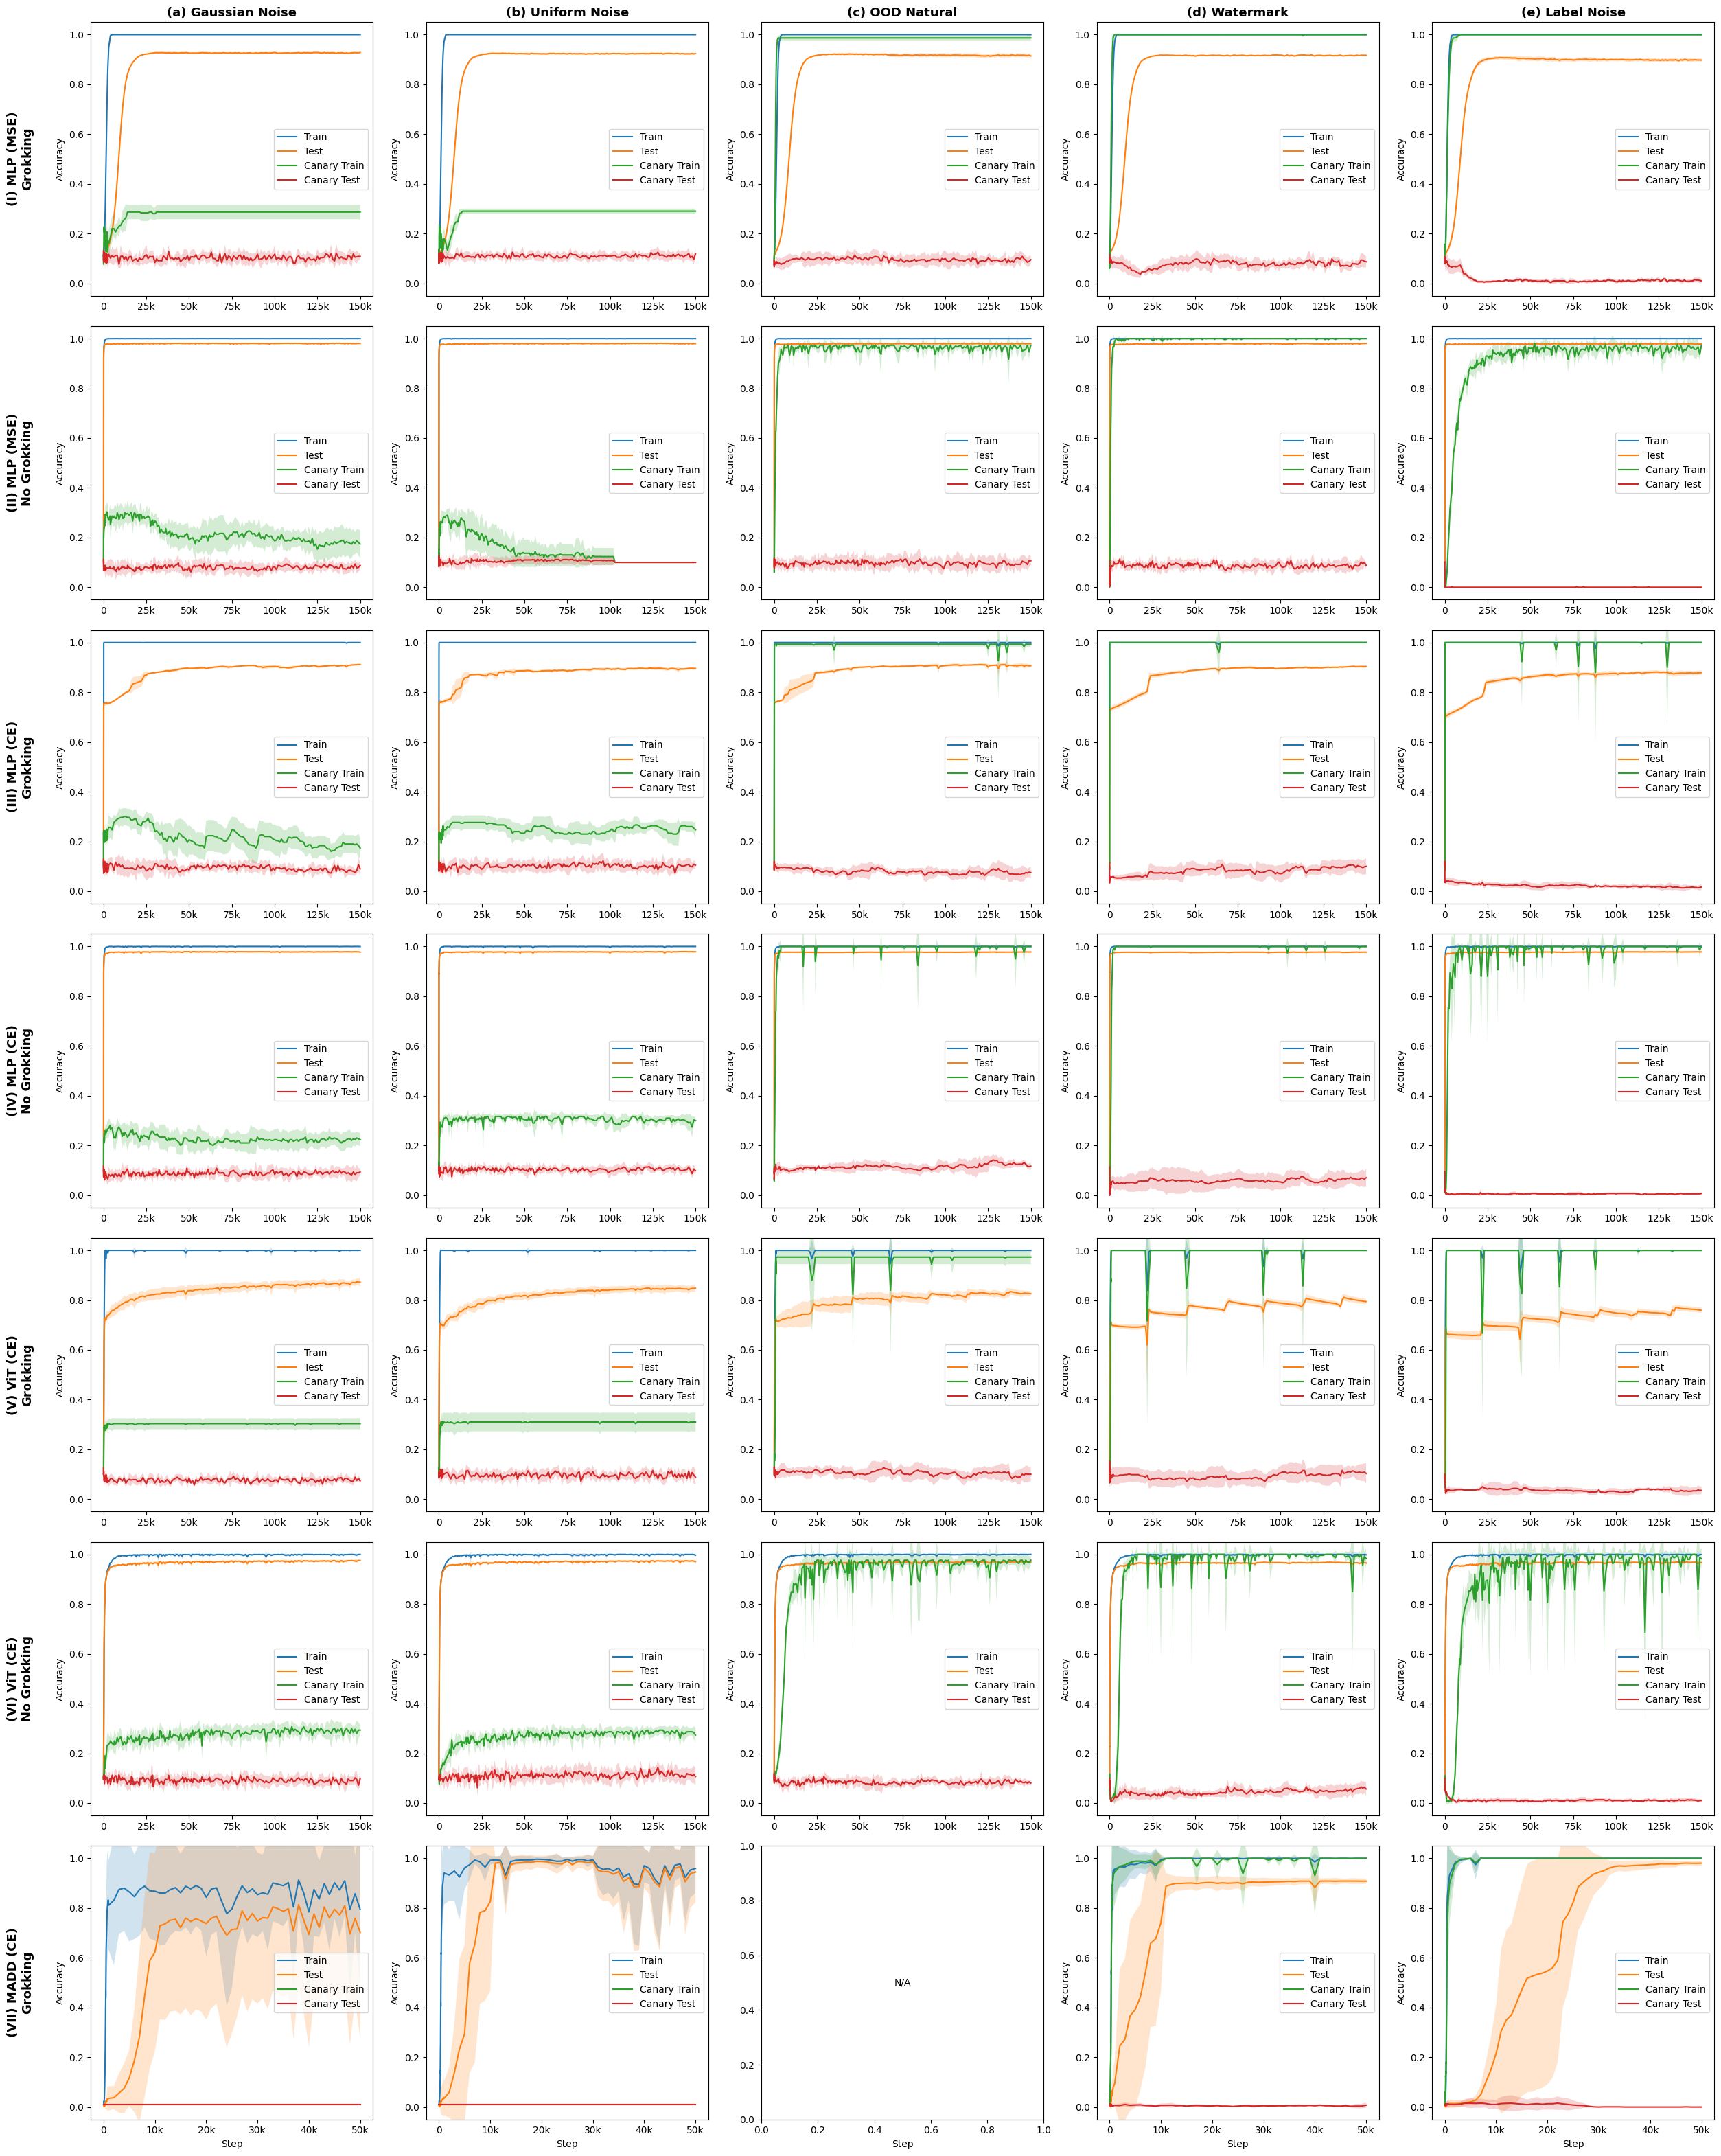

In [212]:
CANARIES = {
    "GAUSSIAN_NOISE": "(a) Gaussian Noise",
    "UNIFORM_NOISE": "(b) Uniform Noise",
    "OOD_NATURAL": "(c) OOD Natural",
    "SQUARE_WATERMARK": "(d) Watermark",
    "LABEL_NOISE": "(e) Label Noise"
}
N_COLS = len(CANARIES)
N_ROWS = len(SETUPS)
TITLES = list(SETUPS.values())

def plot_region(ax, df, metric, label):
    plot = ax.plot(df["step"], df[metric + "_mean"], label=label)
    ax.fill_between(
        df["step"],
        df[metric + "_mean"] - df[metric + "_std"],
        df[metric + "_mean"] + df[metric + "_std"],
        alpha=0.2,
    )
    return plot

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row in range(N_ROWS):
    title = TITLES[row]
    ax = axes[row]

    # Row Title
    ax[0].annotate(
        title,
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )

    # Y-Labels
    if row == N_ROWS - 1:
        for i in range(N_COLS):
            ax[i].set_xlabel("Step")

    for col, (canary, column_name) in enumerate(CANARIES.items()):
        df = (
            metrics_df
            .filter((pl.col("title") == title) & (pl.col("run_name").str.contains(canary)))
            .group_by(["title", "step"])
            .agg([
                cs.numeric().exclude("step").mean().name.suffix("_mean"),
                cs.numeric().exclude("step").std().name.suffix("_std"),
            ])
            .sort(["title", "step"])
        )
        
        if (len(df) <= 0):
            ax[col].text(0.5, 0.5, "N/A", horizontalalignment="center", verticalalignment="center")
            continue

        if row == 0:
            ax[col].set_title(column_name, fontsize=13, fontweight="bold")
        plot_region(ax[col], df, "eval/train/accuracy", "Train")
        plot_region(ax[col], df, "eval/test/accuracy", "Test")
        plot_region(ax[col], df, "eval/train/canary_accuracy", "Canary Train")
        plot_region(ax[col], df, "eval/test/canary_accuracy", "Canary Test")
        ax[col].set_ylabel("Accuracy")
        ax[col].set_ylim(-0.05, 1.05)
        ax[col].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
        ax[col].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
        ax[col].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
        ax[col].legend()

plt.tight_layout()

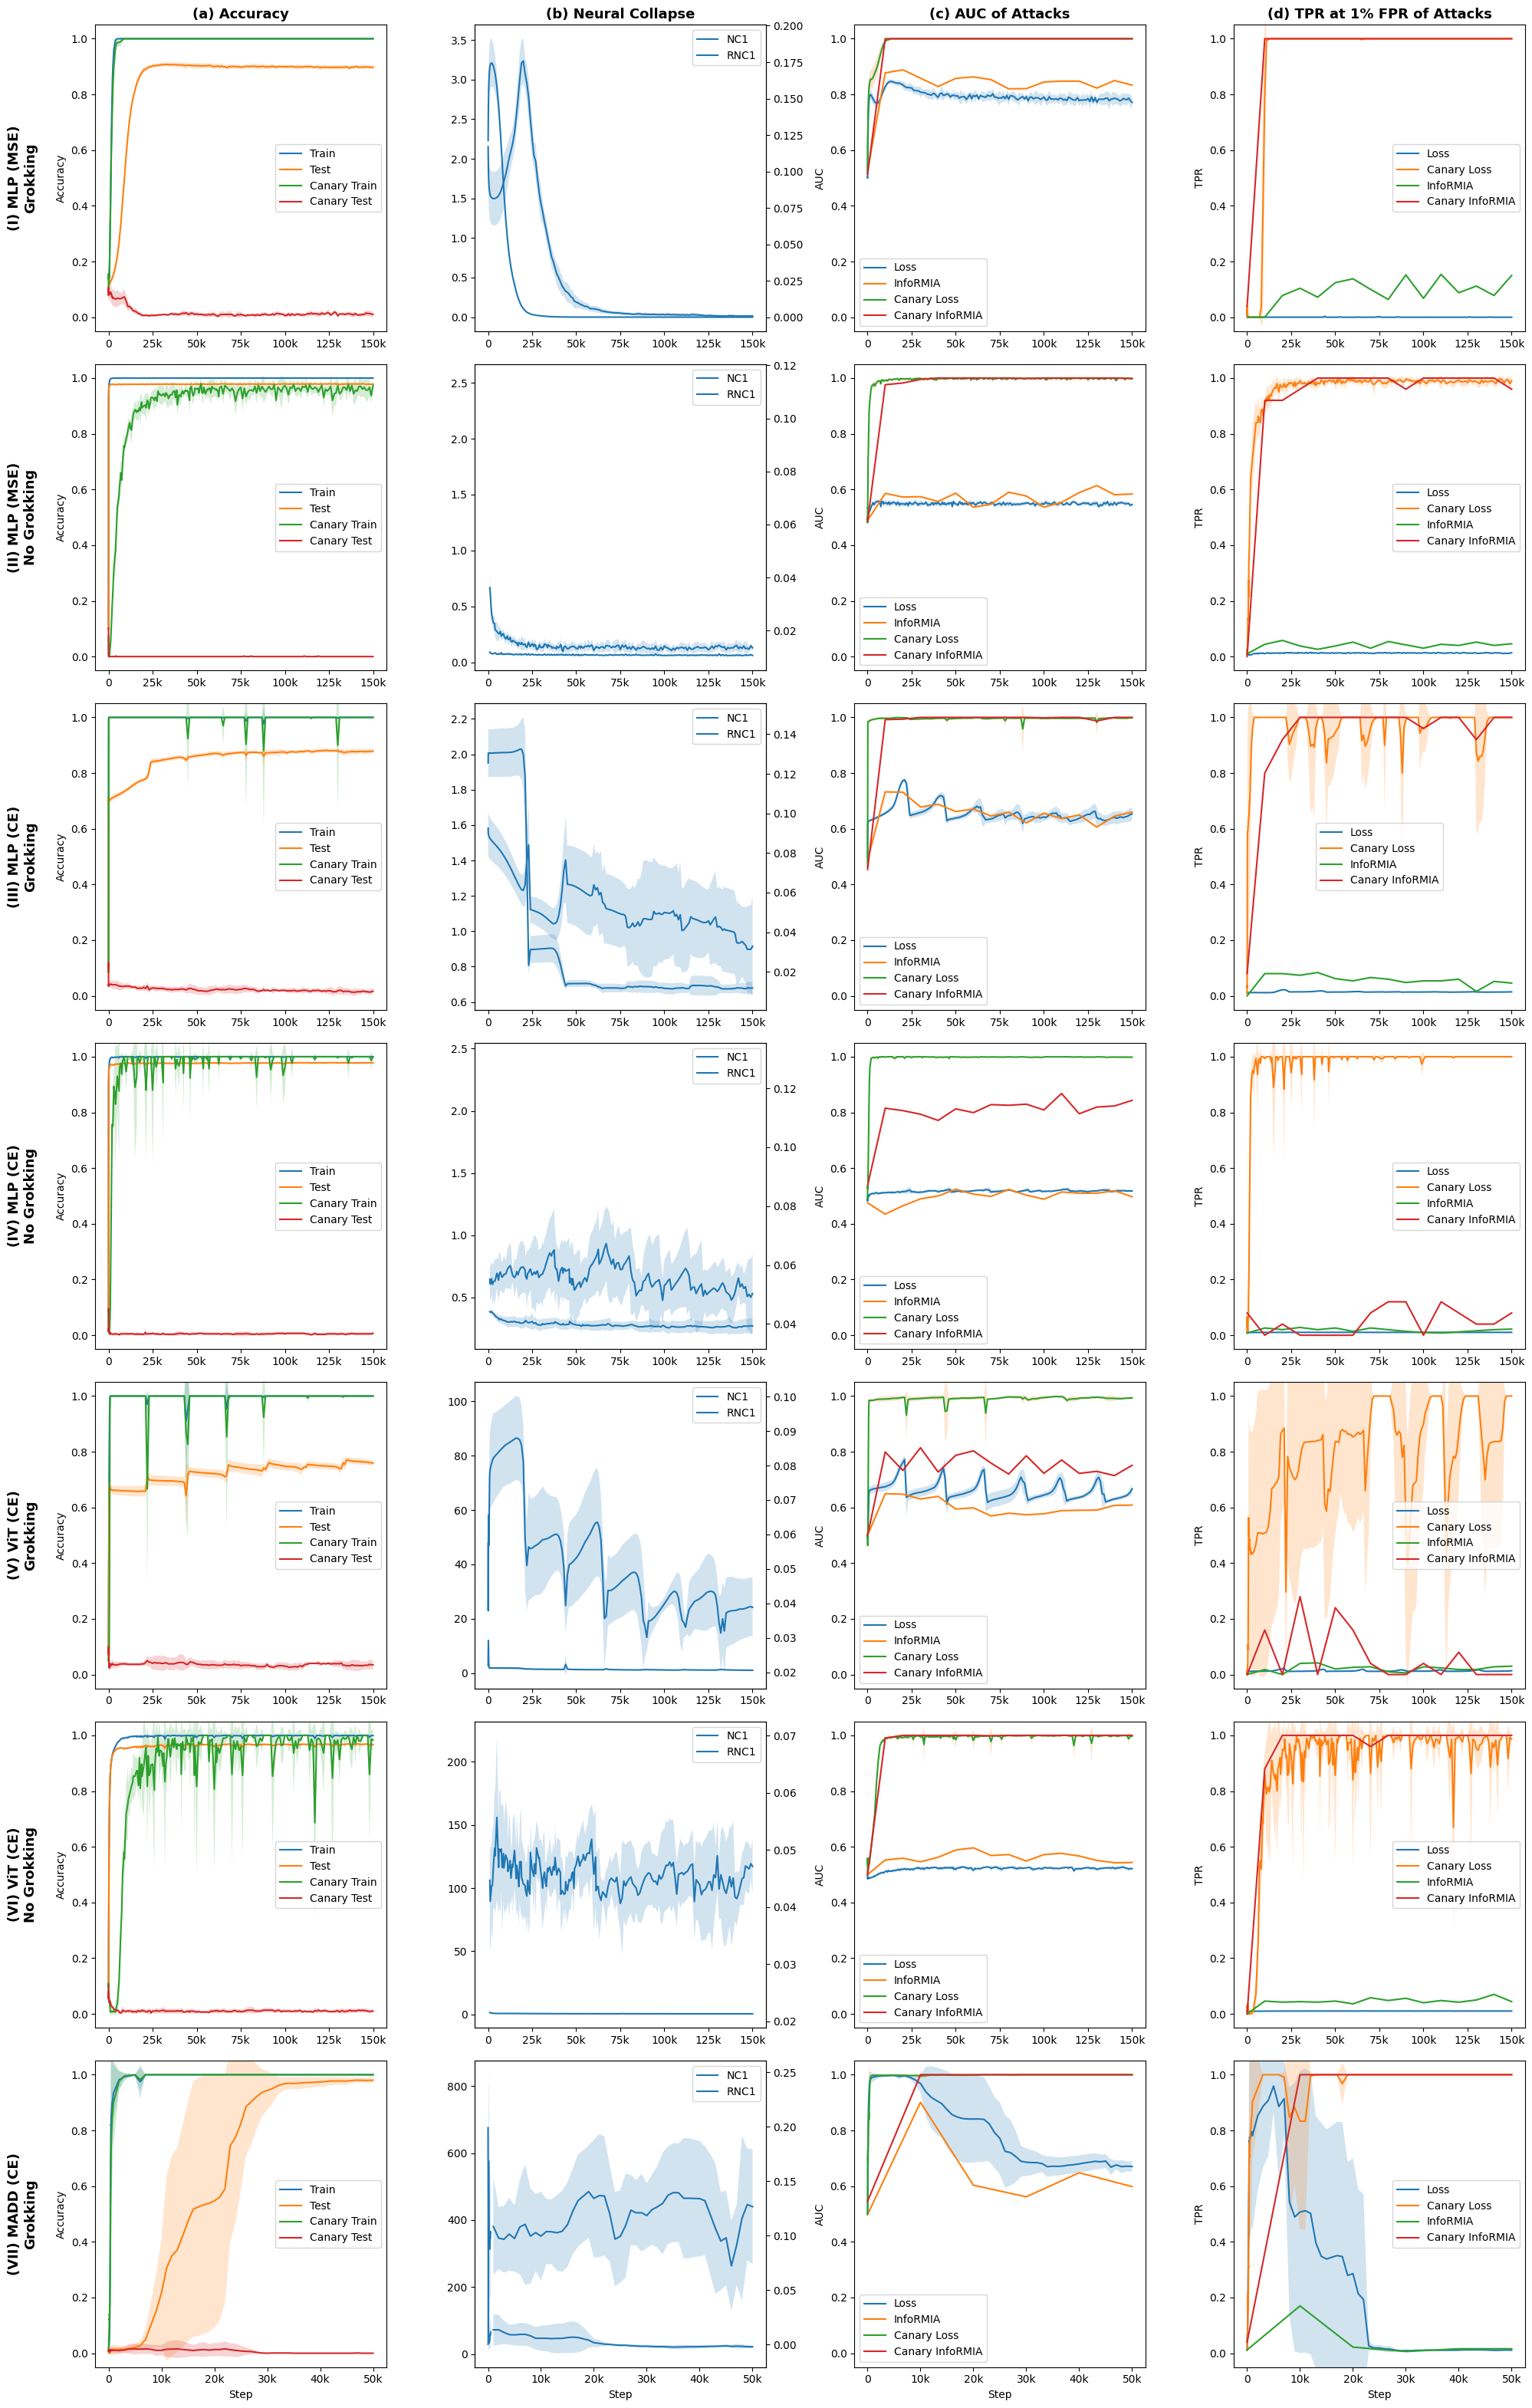

In [216]:
N_COLS = 4
N_ROWS = len(SETUPS)
TITLES = list(SETUPS.values())

label_metrics_df = metrics_df.filter(pl.col("run_name").str.contains("LABEL_NOISE"))
label_info_rmia_df = info_rmia_df.filter(pl.col("run_name").str.contains("LABEL_NOISE"))

def plot_region(ax, df, metric, label):
    plot = ax.plot(df["step"], df[metric + "_mean"], label=label)
    ax.fill_between(
        df["step"],
        df[metric + "_mean"] - df[metric + "_std"],
        df[metric + "_mean"] + df[metric + "_std"],
        alpha=0.2,
    )
    return plot

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row in range(N_ROWS):
    title = TITLES[row]
    ax = axes[row]
    loss = "mse_loss" if "mse" in title else "ce_loss"

    df = (
        label_metrics_df
        .filter(pl.col("title") == title)
        .group_by(["title", "step"])
        .agg([
            cs.numeric().exclude("step").mean().name.suffix("_mean"),
            cs.numeric().exclude("step").std().name.suffix("_std"),
        ])
        .sort(["title", "step"])
    )
    info_df = (
        label_info_rmia_df
        .filter((pl.col("title") == title) & (pl.col("canary") == False))
        .sort(["step"])
    )
    canary_info_df = (
        label_info_rmia_df
        .filter((pl.col("title") == title) & (pl.col("canary") == True))
        .sort(["step"])
    )

    # Row Title
    ax[0].annotate(
        title,
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )

    # Y-Labels
    if row == N_ROWS - 1:
        for i in range(N_COLS):
            ax[i].set_xlabel("Step")

    # Plot
    if row == 0:
        ax[0].set_title("(a) Accuracy", fontsize=13, fontweight="bold")
    plot_region(ax[0], df, "eval/train/accuracy", "Train")
    plot_region(ax[0], df, "eval/test/accuracy", "Test")
    plot_region(ax[0], df, "eval/train/canary_accuracy", "Canary Train")
    plot_region(ax[0], df, "eval/test/canary_accuracy", "Canary Test")
    ax[0].set_ylabel("Accuracy")
    ax[0].set_ylim(-0.05, 1.05)
    ax[0].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[0].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[0].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[0].legend()

    if row == 0:
        ax[1].set_title("(b) Neural Collapse", fontsize=13, fontweight="bold")
    p1 = plot_region(ax[1], df, "eval/nc/nc1", "NC1")
    p2 = plot_region(ax[1].twinx(), df, "eval/nc/rnc1/train", "RNC1")
    ax[1].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[1].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[1].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    plots = p1 + p2
    labels = [l.get_label() for l in plots]
    ax[1].legend(plots, labels)

    if row == 0:
        ax[2].set_title("(c) AUC of Attacks", fontsize=13, fontweight="bold")
    plot_region(ax[2], df, f"eval/attack/{loss}/auc", "Loss")
    ax[2].plot(info_df["step"], info_df["auc"], label="InfoRMIA")
    plot_region(ax[2], df, f"eval/attack/canary_{loss}/auc", "Canary Loss")
    ax[2].plot(canary_info_df["step"], canary_info_df["auc"], label="Canary InfoRMIA")
    ax[2].set_ylabel("AUC")
    ax[2].set_ylim(-0.05, 1.05)
    ax[2].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[2].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[2].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[2].legend()

    if row == 0:
        ax[3].set_title("(d) TPR at 1% FPR of Attacks", fontsize=13, fontweight="bold")
    plot_region(ax[3], df, f"eval/attack/{loss}/tpr-at-fpr/1", "Loss")
    plot_region(ax[3], df, f"eval/attack/canary_{loss}/tpr-at-fpr/1", "Canary Loss")
    ax[3].plot(info_df["step"], info_df["tpr_at_0.01_fpr"], label="InfoRMIA")
    ax[3].plot(canary_info_df["step"], canary_info_df["tpr_at_0.01_fpr"], label="Canary InfoRMIA")
    ax[3].set_ylabel("TPR")
    ax[3].set_ylim(-0.05, 1.05)
    ax[3].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[3].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[3].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[3].legend()

plt.tight_layout()

TODO:
- einheitliches Farbschema
- Linienunterscheidung
- NC1 und RNC1
- Canary Section anpassen, weil jetzt das Modell doch bis 150k geht.